In [6]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import utils

RESULTS_PATH = Path("model_results.json")
if not RESULTS_PATH.exists():
    RESULTS_PATH = Path("BTP/model_results.json")

DATA_DIR = Path("FRED")
if not DATA_DIR.exists():
    DATA_DIR = Path("BTP/FRED")


def add_model_results_to_json(model_results, output_path=RESULTS_PATH):
    """Merge model results into the JSON results file."""
    output_path = Path(output_path)
    existing_results = {}
    if output_path.exists():
        existing_results = json.loads(output_path.read_text(encoding="utf-8"))
    existing_results.update(model_results)
    utils.save_model_results_to_json(existing_results, output_path)
    return existing_results


def load_model_results_from_json(input_path=RESULTS_PATH):
    """Load model results exported as JSON."""
    input_path = Path(input_path)
    if not input_path.exists():
        raise FileNotFoundError(f"Results file not found: {input_path}")
    return json.loads(input_path.read_text(encoding="utf-8"))


def load_targets(data_dir=DATA_DIR):
    """Load target values from the FRED dataset for train, validation, and test splits."""
    return utils.get_target_data(data_dir=data_dir)


def select_models(model_results, model_names=None):
    """Return all models or only the requested model names."""
    if model_names is None:
        return model_results
    missing_names = [name for name in model_names if name not in model_results]
    if missing_names:
        raise KeyError(f"Unknown model names: {missing_names}")
    return {name: model_results[name] for name in model_names}


def get_all_model_names_from_json(model_results):
    """Return all model names stored in the JSON results."""
    return list(model_results.keys())


def evaluate_models_with_targets(model_results, targets, split="test", model_names=None):
    """Evaluate models against target values computing both regression metrics (MAE, MSE, RMSE, MAPE) and Directional metrics."""
    selected_results = select_models(model_results, model_names)
    target_series = targets[split] if isinstance(targets, dict) else targets
    
    rows = []
    for model_name, result in selected_results.items():
        predictions = result.get("predictions", {}).get(split)
        if predictions is None:
            continue
        
        # Calculate full directional and regression metrics
        dir_metrics = utils.calculate_directional_metrics(predictions, target_series)
        
        rows.append(
            {
                "model_name": model_name,
                "split": split,
                "mae": round(dir_metrics["mae"], 4),
                "mse": round(dir_metrics["mse"], 4),
                "rmse": round(dir_metrics["rmse"], 4),
                "mape (%)": round(dir_metrics["mape"], 2),
                "directional_acc (%)": round(dir_metrics["directional_accuracy"], 2),
                "correct_days": f"{dir_metrics['correct_days']} / {dir_metrics['total_days']}",
                "up_precision (%)": round(dir_metrics["up_precision"], 2),
                "down_precision (%)": round(dir_metrics["down_precision"], 2),
                "up_recall (%)": round(dir_metrics["up_recall"], 2),
                "down_recall (%)": round(dir_metrics["down_recall"], 2),
                "up_f1 (%)": round(dir_metrics["up_f1"], 2),
                "down_f1 (%)": round(dir_metrics["down_f1"], 2),
            }
        )
    if not rows:
        raise ValueError(f"No predictions found for split: {split}")
    return pd.DataFrame(rows).sort_values("mae").reset_index(drop=True)


def evaluate_models_from_json(model_results, split="test", model_names=None):
    """Display MAE and MSE for selected models from the JSON results (backward compatible)."""
    selected_results = select_models(model_results, model_names)
    rows = []
    for model_name, result in selected_results.items():
        split_metrics = result.get("metrics", {}).get(split)
        if split_metrics is None:
            continue
        rows.append(
            {
                "model_name": model_name,
                "split": split,
                "mae": split_metrics["mae"],
                "mse": split_metrics["mse"],
            }
        )
    if not rows:
        raise ValueError(f"No metrics found for split: {split}")
    return pd.DataFrame(rows).sort_values("mae").reset_index(drop=True)


def plot_directional_accuracy_comparison(train_metrics, test_metrics, figsize=(14, 6)):
    """Compare Directional Accuracy (%) across models for train and test splits."""
    models = list(test_metrics["model_name"])
    
    merged = pd.merge(
        train_metrics[["model_name", "directional_acc (%)"]].rename(columns={"directional_acc (%)": "Train Directional Acc (%)"}),
        test_metrics[["model_name", "directional_acc (%)"]].rename(columns={"directional_acc (%)": "Test Directional Acc (%)"}),
        on="model_name",
        how="outer"
    ).fillna(0)
    
    x = np.arange(len(merged))
    width = 0.35
    
    fig, ax = plt.subplots(figsize=figsize)
    bars1 = ax.bar(x - width/2, merged["Train Directional Acc (%)"], width, label="Train Directional Acc (%)", color="#1976D2", alpha=0.9)
    bars2 = ax.bar(x + width/2, merged["Test Directional Acc (%)"], width, label="Test Directional Acc (%)", color="#388E3C", alpha=0.9)
    
    ax.axhline(50.0, color="gray", linestyle="--", alpha=0.7, label="Random Guess Baseline (50%)")
    ax.set_ylabel("Directional Accuracy (%)", fontsize=11)
    ax.set_title("Model Directional Accuracy Comparison (UP vs DOWN Movement)", fontsize=13, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(merged["model_name"], rotation=25, ha="right", fontsize=10)
    ax.set_ylim(0, 100)
    ax.legend(loc="lower right")
    ax.grid(True, linestyle=":", alpha=0.6, axis="y")
    
    for bar in list(bars1) + list(bars2):
        height = bar.get_height()
        if height > 0:
            ax.annotate(f"{height:.1f}%",
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha="center", va="bottom", fontsize=9, fontweight="bold")
                        
    fig.tight_layout()
    plt.show()
    return fig, ax


def plot_all_predictions_with_targets(model_results, targets, split="test", model_names=None, figsize=(16, 7)):
    """Plot stored predictions for all selected models alongside the actual ground truth targets."""
    selected_results = select_models(model_results, model_names)
    target_series = targets[split] if isinstance(targets, dict) else targets
    dates = target_series.index if hasattr(target_series, "index") else np.arange(len(target_series))
    
    fig, ax = plt.subplots(figsize=figsize)
    # Plot Ground Truth in bold
    ax.plot(dates, target_series.values, label="Actual Target (INR)", color="black", linewidth=2.5, zorder=5)
    
    colors = ["#D32F2F", "#1976D2", "#388E3C", "#7B1FA2", "#F57C00", "#00796B"]
    for idx, (model_name, result) in enumerate(selected_results.items()):
        predictions = result.get("predictions", {}).get(split)
        if predictions is None:
            continue
        preds = np.asarray(predictions)
        x_vals = dates[-len(preds):]
        color = colors[idx % len(colors)]
        ax.plot(x_vals, preds, label=model_name, color=color, linewidth=1.4, linestyle="--", alpha=0.85)
        
    ax.set_title(f"All Models vs Ground Truth Target ({split.title()} Split)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Date" if hasattr(target_series, "index") else "Time Steps", fontsize=11)
    ax.set_ylabel("INR Exchange Rate", fontsize=11)
    ax.legend(loc="upper left", framealpha=0.9)
    ax.grid(True, linestyle=":", alpha=0.6)
    fig.tight_layout()
    plt.show()
    return fig, ax


def plot_all_model_directional_candles(
    model_results,
    targets,
    split="test",
    model_names=None,
    zoom_range=None,
    correct_color="#1E88E5",
    incorrect_color="#FF4081",
):
    """Plot directional prediction candles/boxes (Blue = Correct, Pink = Incorrect) for all selected models."""
    selected_results = select_models(model_results, model_names)
    target_series = targets[split] if isinstance(targets, dict) else targets
    dates = target_series.index if hasattr(target_series, "index") else None

    figures = []
    for model_name, result in selected_results.items():
        predictions = result.get("predictions", {}).get(split)
        if predictions is None:
            continue
        fig, ax = utils.plot_directional_candles(
            predictions=predictions,
            targets=target_series,
            dates=dates,
            model_name=model_name,
            split=split,
            zoom_range=zoom_range,
            correct_color=correct_color,
            incorrect_color=incorrect_color,
        )
        figures.append((model_name, fig, ax))
    return figures


def plot_predictions_from_json(model_results, split="test", model_names=None):
    """Plot stored predictions for selected models from the JSON results."""
    selected_results = select_models(model_results, model_names)
    figure, axis = plt.subplots(figsize=(16, 8))
    plotted_models = 0
    for model_name, result in selected_results.items():
        predictions = result.get("predictions", {}).get(split)
        if predictions is None:
            continue
        axis.plot(predictions, label=model_name)
        plotted_models += 1
    if not plotted_models:
        raise ValueError(f"No predictions found for split: {split}")
    axis.set_title(f"Model Predictions from JSON ({split.title()} Split)")
    axis.set_xlabel("Time")
    axis.set_ylabel("Predicted INR")
    axis.legend()
    axis.grid(True)
    figure.tight_layout()
    plt.show()
    return figure, axis

In [7]:
# 1. Load Model Results & Ground Truth Target Values
model_results = load_model_results_from_json()
targets = load_targets()

print(f"Available models in JSON: {get_all_model_names_from_json(model_results)}")
print(f"Loaded target splits: Train={len(targets['train'])}, Validation={len(targets['validation'])}, Test={len(targets['test'])} days")

Available models in JSON: ['Naive', 'Moving Average', 'ARIMA', 'XGBoost', 'Linear Regression', 'Deep Learning', 'Linear Regression with Technical Indicators', 'Deep Learning with Technical Indicators', 'Deep Learning with Technical Indicators and Temporal Features', 'LSTM with Technical Indicators and Temporal Features']
Loaded target splits: Train=5524, Validation=690, Test=691 days


In [8]:
# 2. Select Models to Compare
models_to_compare = [
    'Naive',
    'Moving Average',
    'Linear Regression with Technical Indicators',
    'Deep Learning with Technical Indicators',
    'Deep Learning with Technical Indicators and Temporal Features',
    'LSTM with Technical Indicators and Temporal Features'
]

# Compute All Metrics (MAE, MSE, RMSE, MAPE & Directional UP/DOWN Accuracy)
train_metrics = evaluate_models_with_targets(
    model_results,
    targets=targets,
    split="train",
    model_names=models_to_compare,
)
test_metrics = evaluate_models_with_targets(
    model_results,
    targets=targets,
    split="test",
    model_names=models_to_compare,
)

print("=== TRAIN SPLIT: Regression (MAE, MSE, RMSE, MAPE) & Directional Metrics ===")
display(train_metrics)

print("\n=== TEST SPLIT: Regression (MAE, MSE, RMSE, MAPE) & Directional Metrics ===")
display(test_metrics)

=== TRAIN SPLIT: Regression (MAE, MSE, RMSE, MAPE) & Directional Metrics ===


,model_name,split,mae,mse,rmse,mape (%),directional_acc (%),correct_days,up_precision (%),down_precision (%),up_recall (%),down_recall (%),up_f1 (%),down_f1 (%)
0,Moving Average,train,0.1813,0.1232,0.3510,0.33,55.35,3057 / 5523,58.22,52.33,56.31,54.26,57.25,53.28
1,Deep Learning with Technical Indicators,train,0.2042,0.1050,0.3241,0.37,69.71,3839 / 5507,71.94,67.31,70.32,69.03,71.12,68.16
2,Deep Learning with Technical Indicators and Te...,train,0.2053,0.1062,0.3258,0.38,69.89,3849 / 5507,72.07,67.54,70.59,69.10,71.32,68.31
3,Naive,train,0.2082,0.1293,0.3596,0.38,54.83,3028 / 5523,57.27,51.91,58.73,50.41,57.99,51.15
4,LSTM with Technical Indicators and Temporal Fe...,train,0.2103,0.1113,0.3336,0.39,69.60,3806 / 5468,71.64,67.38,70.56,68.53,71.10,67.95
5,Linear Regression with Technical Indicators,train,0.2153,0.1138,0.3373,0.40,69.15,3808 / 5507,69.34,68.90,75.01,62.53,72.06,65.56



=== TEST SPLIT: Regression (MAE, MSE, RMSE, MAPE) & Directional Metrics ===


,model_name,split,mae,mse,rmse,mape (%),directional_acc (%),correct_days,up_precision (%),down_precision (%),up_recall (%),down_recall (%),up_f1 (%),down_f1 (%)
0,Deep Learning with Technical Indicators and Te...,test,0.2104,0.1003,0.3167,0.24,51.60,355 / 688,55.29,45.96,61.01,40.19,58.01,42.88
1,Deep Learning with Technical Indicators,test,0.2198,0.1080,0.3287,0.25,52.62,362 / 688,60.41,48.31,39.26,68.81,47.59,56.76
2,Linear Regression with Technical Indicators,test,0.2457,0.1196,0.3459,0.28,49.42,340 / 688,62.18,46.75,19.63,85.53,29.84,60.45
3,LSTM with Technical Indicators and Temporal Fe...,test,0.3168,0.2116,0.4600,0.35,48.84,317 / 649,57.38,45.49,29.25,73.10,38.75,56.08


=== Train Split: MAE, MSE, RMSE Comparison ===


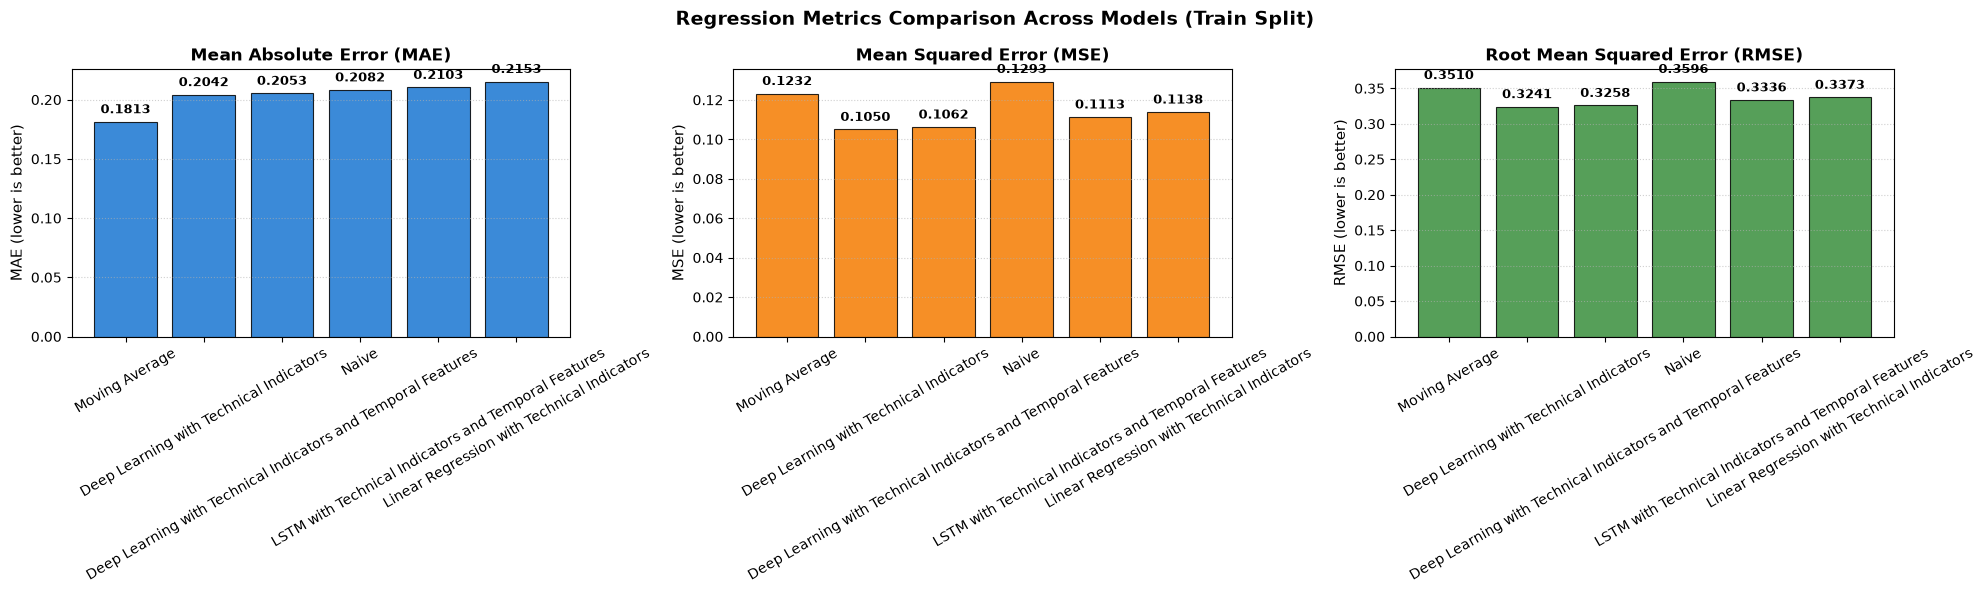

=== Test Split: MAE, MSE, RMSE Comparison ===


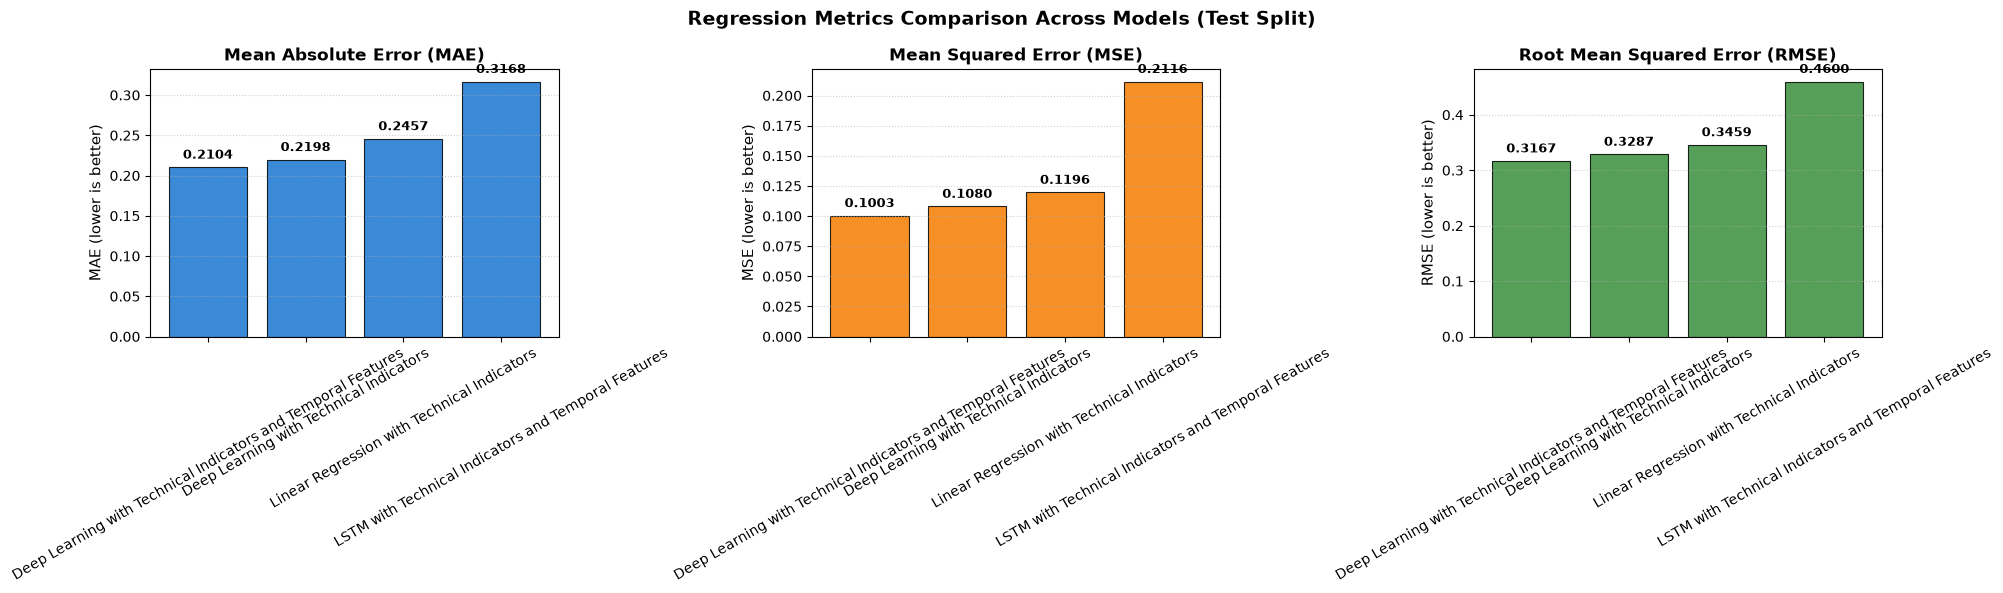

(<Figure size 2000x600 with 3 Axes>,
 array([<Axes: title={'center': 'Mean Absolute Error (MAE)'}, ylabel='MAE (lower is better)'>,
        <Axes: title={'center': 'Mean Squared Error (MSE)'}, ylabel='MSE (lower is better)'>,
        <Axes: title={'center': 'Root Mean Squared Error (RMSE)'}, ylabel='RMSE (lower is better)'>],
       dtype=object))

In [9]:
# 3. Compare Previous Regression Metrics (MAE, MSE, RMSE) Across Models
print("=== Train Split: MAE, MSE, RMSE Comparison ===")
utils.plot_model_metrics(train_metrics, split="train")

print("=== Test Split: MAE, MSE, RMSE Comparison ===")
utils.plot_model_metrics(test_metrics, split="test")

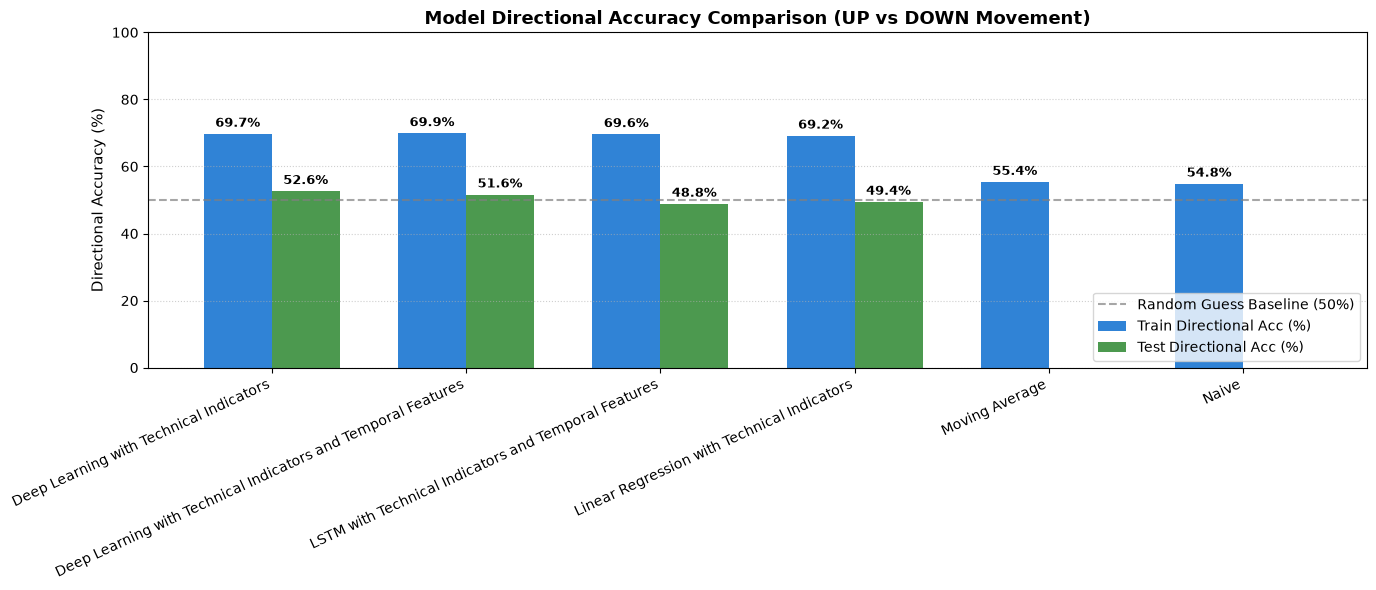

(<Figure size 1400x600 with 1 Axes>,
 <Axes: title={'center': 'Model Directional Accuracy Comparison (UP vs DOWN Movement)'}, ylabel='Directional Accuracy (%)'>)

In [10]:
# 4. Compare Directional Accuracy (%) Across Models (Train vs Test)
plot_directional_accuracy_comparison(train_metrics, test_metrics)

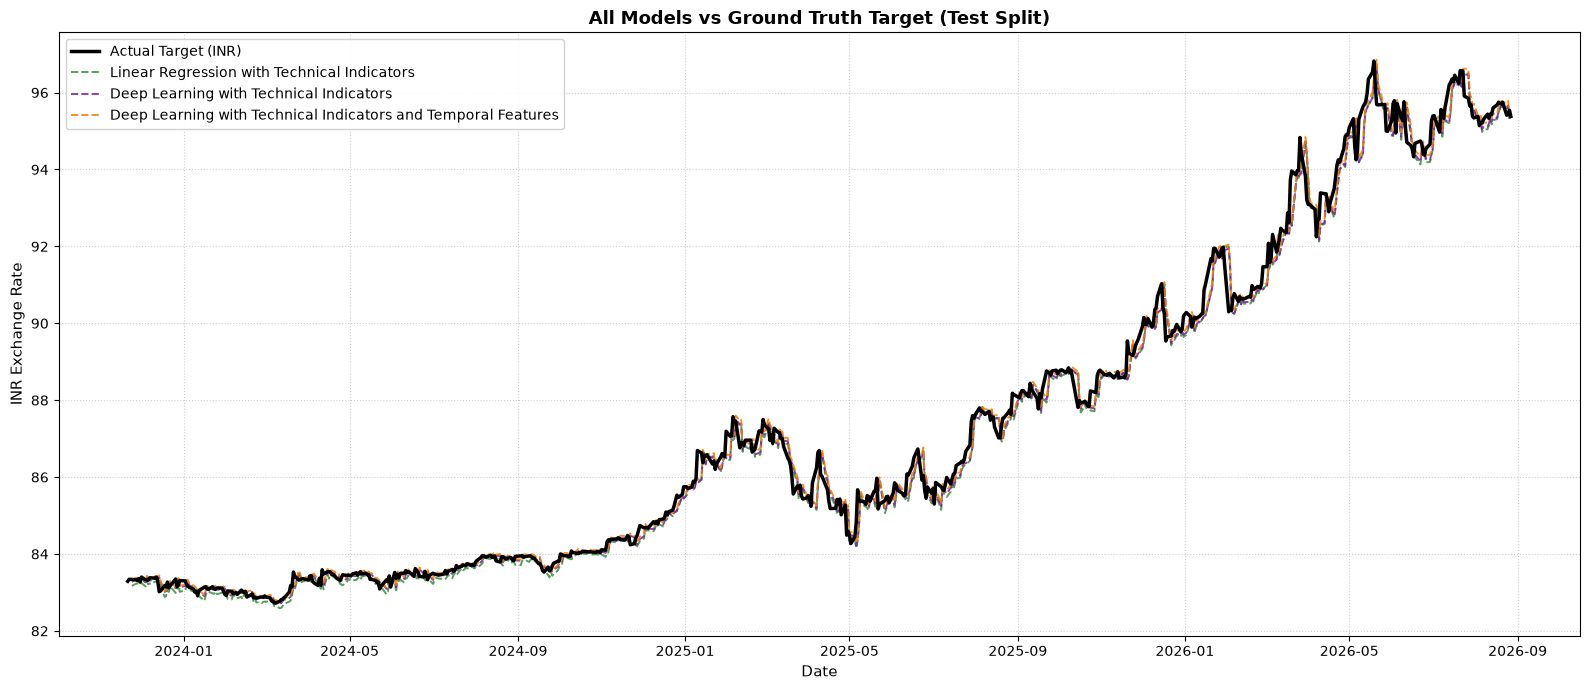

(<Figure size 1600x700 with 1 Axes>,
 <Axes: title={'center': 'All Models vs Ground Truth Target (Test Split)'}, xlabel='Date', ylabel='INR Exchange Rate'>)

In [6]:
# 5. Compare Model Predictions against Actual Ground Truth Target
plot_all_predictions_with_targets(
    model_results,
    targets=targets,
    split="test",
    model_names=models_to_compare,
)

Directional Evaluation Graphs (Blue = Correct UP/DOWN Prediction, Pink = Incorrect Prediction):


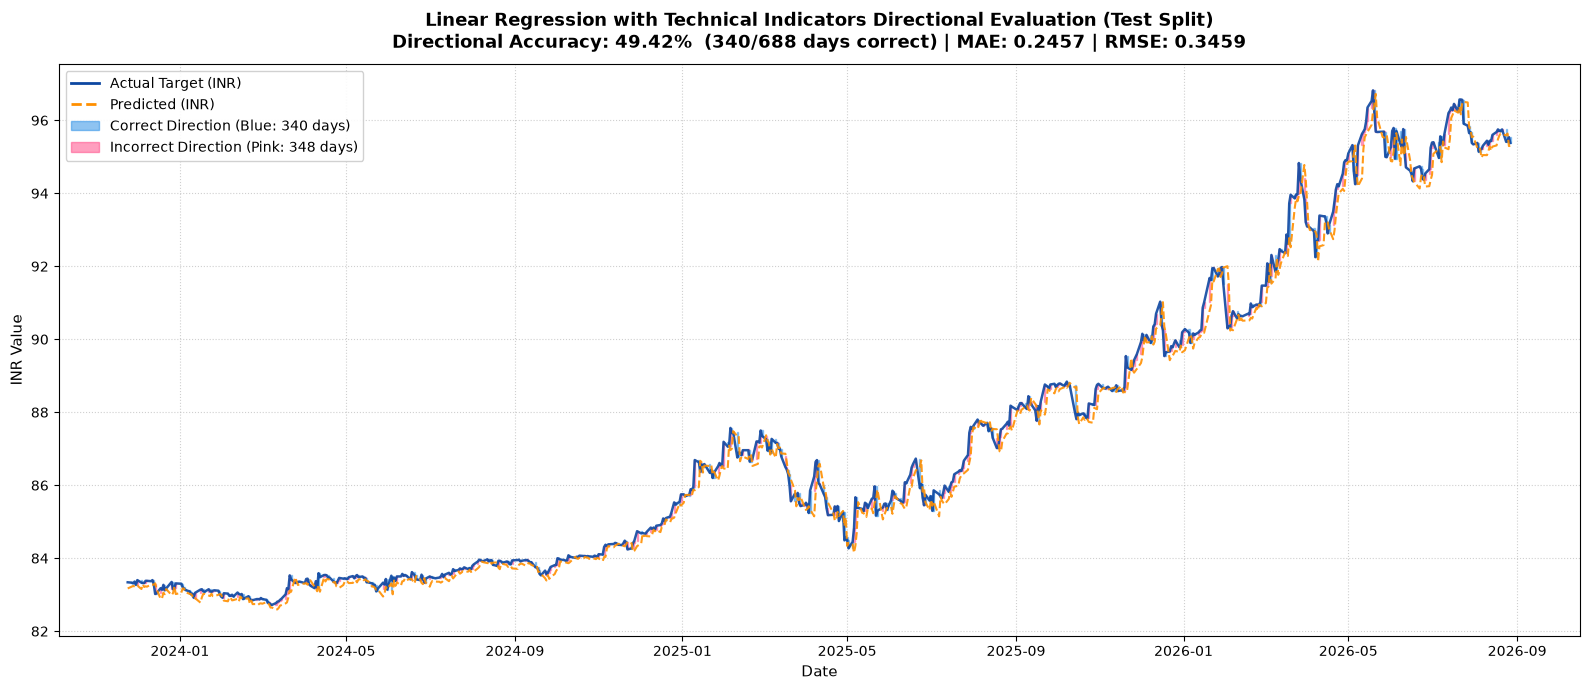

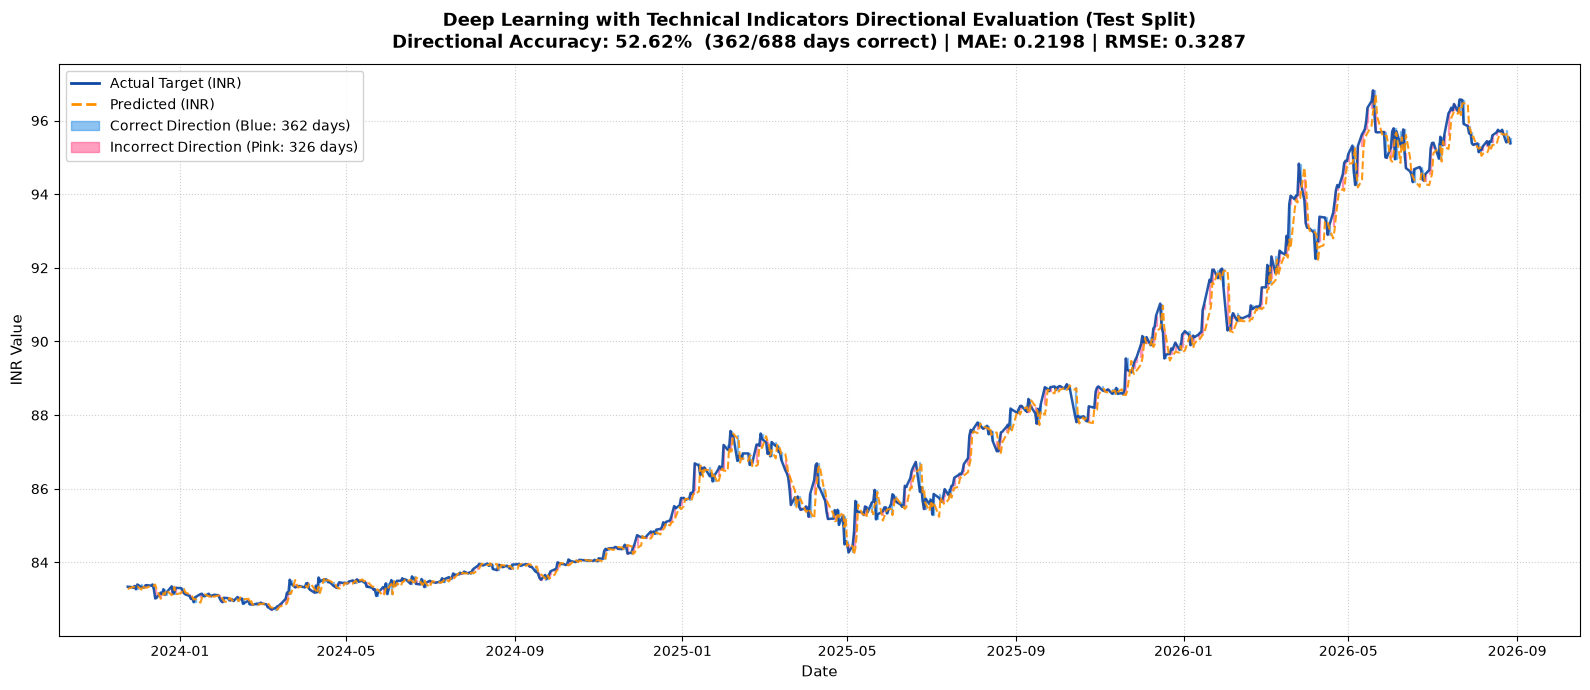

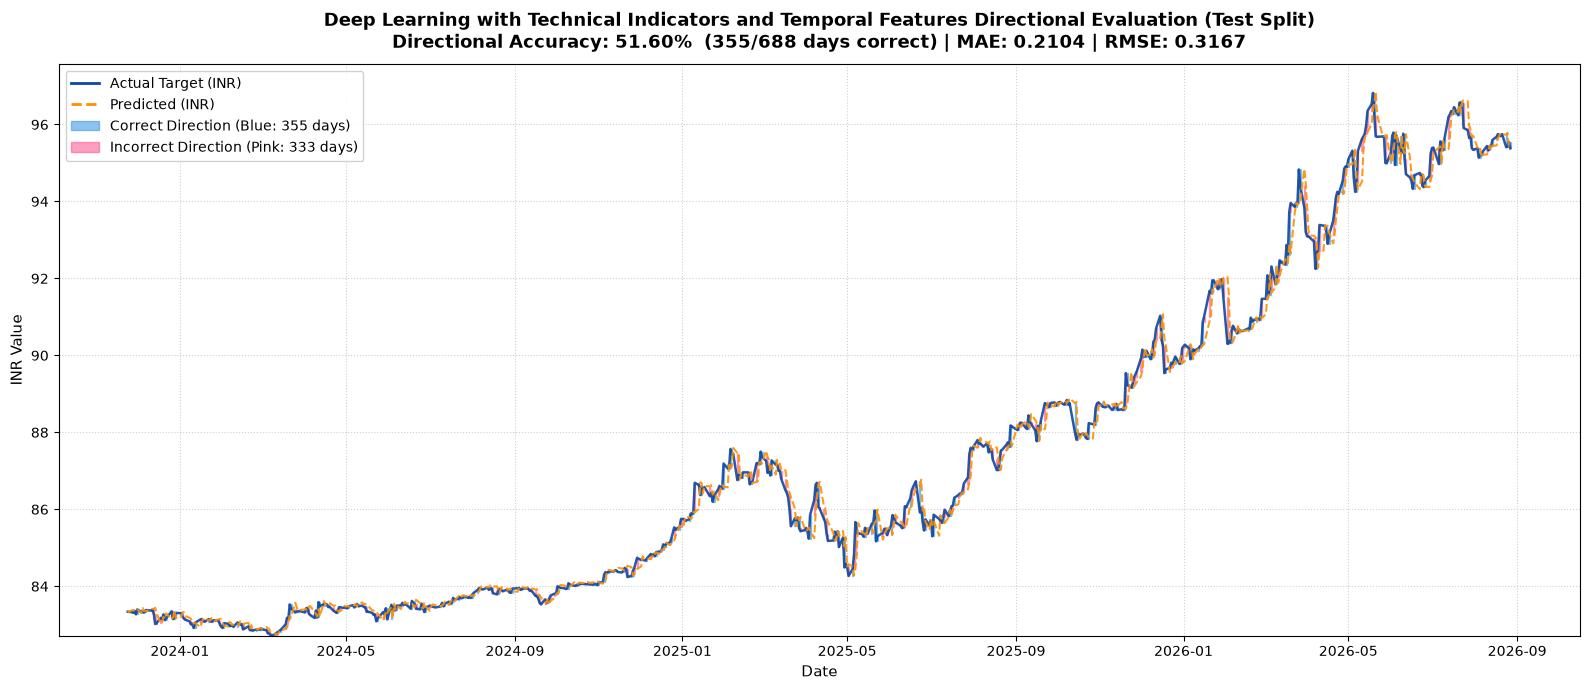

[('Linear Regression with Technical Indicators',
  <Figure size 1600x700 with 1 Axes>,
  <Axes: title={'center': 'Linear Regression with Technical Indicators Directional Evaluation (Test Split)\nDirectional Accuracy: 49.42%  (340/688 days correct) | MAE: 0.2457 | RMSE: 0.3459'}, xlabel='Date', ylabel='INR Value'>),
 ('Deep Learning with Technical Indicators',
  <Figure size 1600x700 with 1 Axes>,
  <Axes: title={'center': 'Deep Learning with Technical Indicators Directional Evaluation (Test Split)\nDirectional Accuracy: 52.62%  (362/688 days correct) | MAE: 0.2198 | RMSE: 0.3287'}, xlabel='Date', ylabel='INR Value'>),
 ('Deep Learning with Technical Indicators and Temporal Features',
  <Figure size 1600x700 with 1 Axes>,
  <Axes: title={'center': 'Deep Learning with Technical Indicators and Temporal Features Directional Evaluation (Test Split)\nDirectional Accuracy: 51.60%  (355/688 days correct) | MAE: 0.2104 | RMSE: 0.3167'}, xlabel='Date', ylabel='INR Value'>)]

In [7]:
# 6. Plot Directional Candle/Box Evaluation (Blue = Correct Direction, Pink = Incorrect Direction)
print("Directional Evaluation Graphs (Blue = Correct UP/DOWN Prediction, Pink = Incorrect Prediction):")
plot_all_model_directional_candles(
    model_results,
    targets=targets,
    split="test",
    model_names=models_to_compare,
)

Zoomed View (Last 100 Days) - Blue = Correct, Pink = Incorrect:


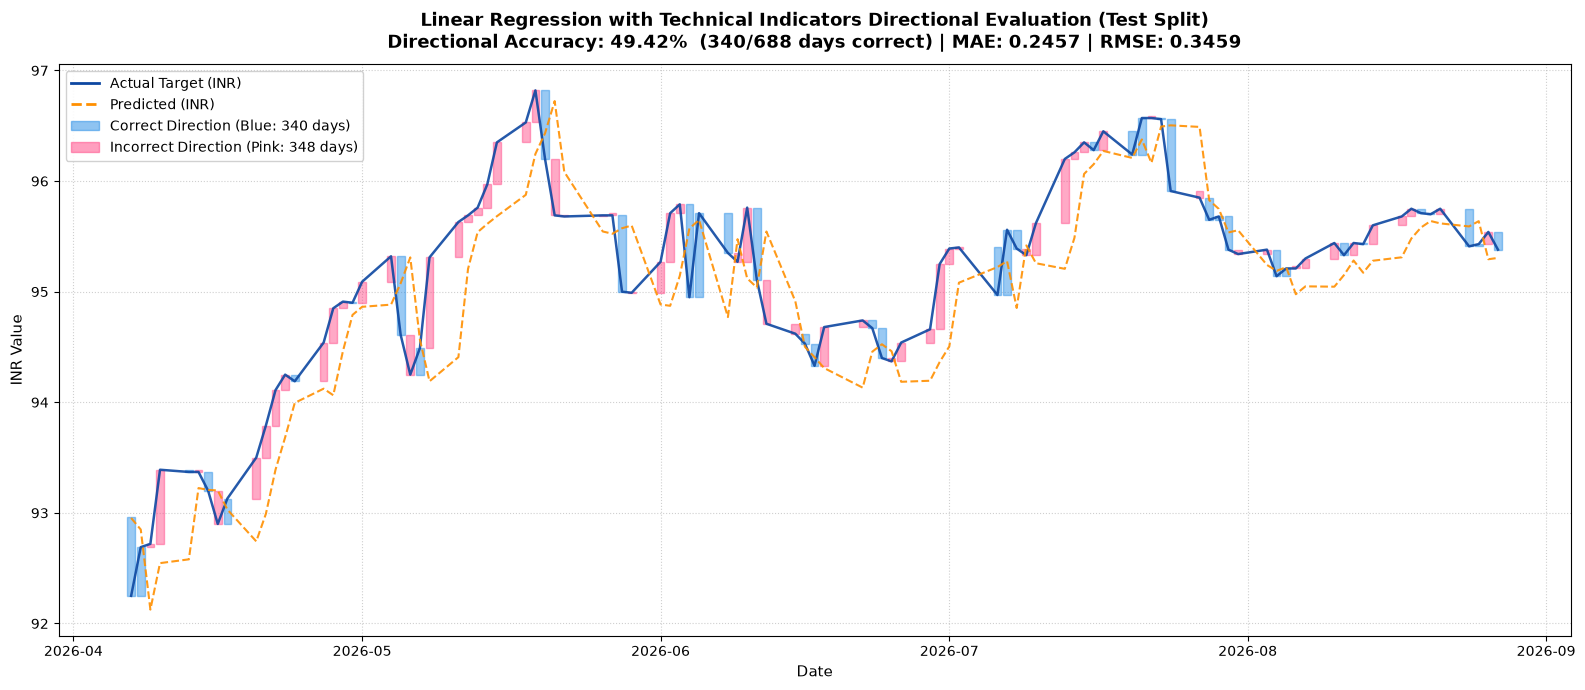

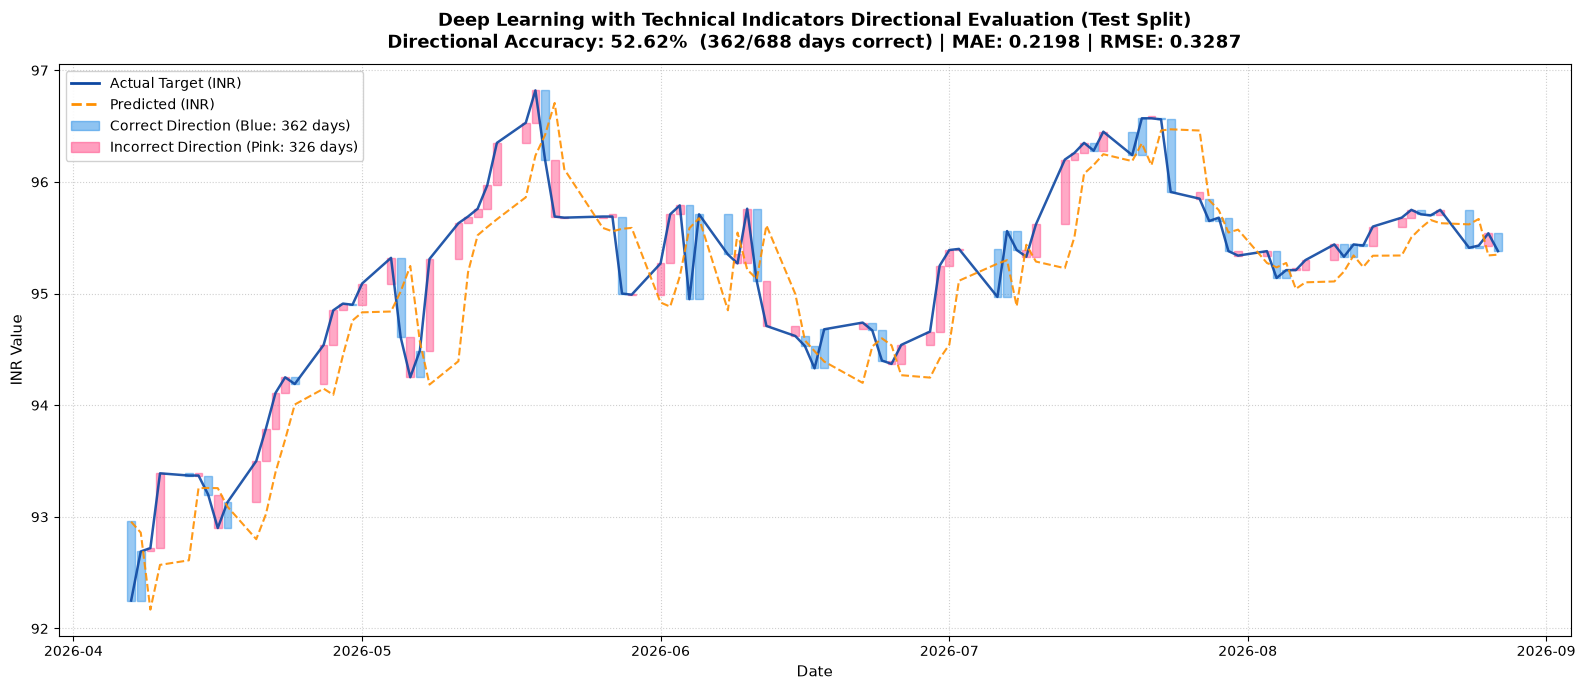

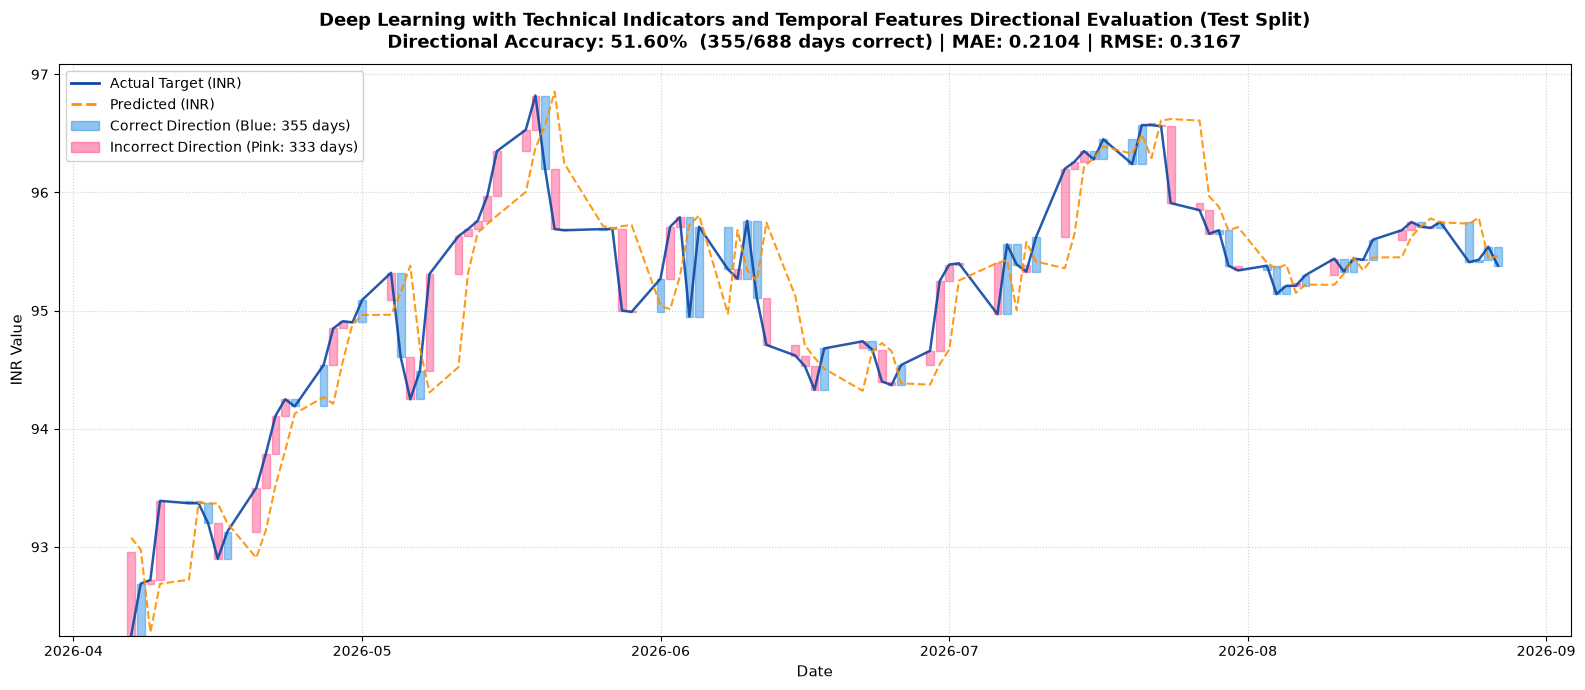

[('Linear Regression with Technical Indicators',
  <Figure size 1600x700 with 1 Axes>,
  <Axes: title={'center': 'Linear Regression with Technical Indicators Directional Evaluation (Test Split)\nDirectional Accuracy: 49.42%  (340/688 days correct) | MAE: 0.2457 | RMSE: 0.3459'}, xlabel='Date', ylabel='INR Value'>),
 ('Deep Learning with Technical Indicators',
  <Figure size 1600x700 with 1 Axes>,
  <Axes: title={'center': 'Deep Learning with Technical Indicators Directional Evaluation (Test Split)\nDirectional Accuracy: 52.62%  (362/688 days correct) | MAE: 0.2198 | RMSE: 0.3287'}, xlabel='Date', ylabel='INR Value'>),
 ('Deep Learning with Technical Indicators and Temporal Features',
  <Figure size 1600x700 with 1 Axes>,
  <Axes: title={'center': 'Deep Learning with Technical Indicators and Temporal Features Directional Evaluation (Test Split)\nDirectional Accuracy: 51.60%  (355/688 days correct) | MAE: 0.2104 | RMSE: 0.3167'}, xlabel='Date', ylabel='INR Value'>)]

In [8]:
# 7. Zoomed View (Last 100 Days) to inspect daily Blue/Pink Candle Boxes up close
print("Zoomed View (Last 100 Days) - Blue = Correct, Pink = Incorrect:")
plot_all_model_directional_candles(
    model_results,
    targets=targets,
    split="test",
    model_names=models_to_compare,
    zoom_range=100,
)